# 415 – Quantum Support Vector Machine (QSVM) with a Quantum Kernel

So far the quantum circuit was the *model* and we trained its weights.  A **quantum kernel**
uses the circuit differently: it only *measures how similar two data points are*.

**Kernel methods in one paragraph.**  A support vector machine (SVM) separates classes with
the widest possible margin.  It never needs the data points themselves – only the **kernel**
$k(x, x')$, a similarity score for every pair.  A kernel is an inner product in some
(possibly huge) *feature space*: $k(x,x') = \langle\phi(x), \phi(x')\rangle$.

**The quantum kernel.**  Let the feature map prepare the state $|\phi(x)\rangle$.  Then

$$k(x, x') = |\langle \phi(x) | \phi(x') \rangle|^2,$$

the **fidelity** of the two states – exactly what the swap test (`002-006`) estimates.  The
feature space is the $2^n$-dimensional space of quantum states, which can be hard to simulate
classically.  `FidelityQuantumKernel` computes all these overlaps, and `QSVC` hands them to
scikit-learn's SVM.  There are **no circuit weights to train**.

**You will learn to** build a quantum kernel, train a `QSVC`, visualise kernel matrices and
compare against a classical RBF-kernel SVM on two datasets.

**Prerequisites:** `002-QuantumCircuits-006-SwapTest`, `402`, `413`.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.datasets import ad_hoc_data
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.utils import algorithm_globals
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.svm import SVC

seed = 10599
algorithm_globals.random_seed = seed
def plot_kernels(quantum, classical, title):
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    axs[0].imshow(np.asmatrix(quantum), interpolation='nearest', origin='upper', cmap='bone_r')
    axs[0].set_title(f'{title}: quantum kernel')
    axs[1].imshow(np.asmatrix(classical), interpolation='nearest', origin='upper', cmap='bone_r')
    axs[1].set_title(f'{title}: classical RBF kernel')
    plt.show()

## Part 1 – the ad hoc dataset

The same data and split as in `413`.

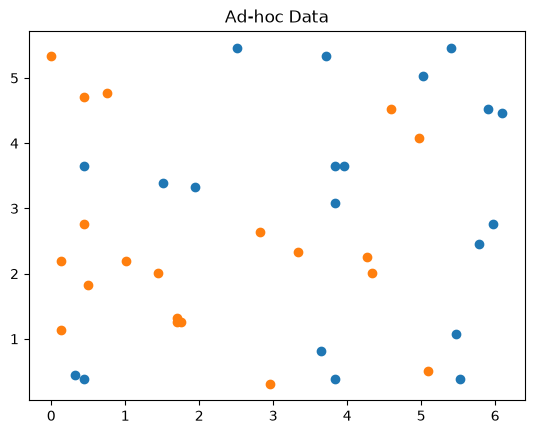

{'A': 0, 'B': 1}


In [3]:
feature_dim = 2
# ad_hoc_data now returns feature/label arrays (class 0 = 'A', class 1 = 'B') instead of
# {class: samples} dictionaries. We draw 30 test points per class from the same distribution:
# 10 for testing, 10 as `datapoints` to predict and 10 as `more_datapoints`.
train_features, train_labels, test_all, test_all_labels = ad_hoc_data(
    training_size=20, test_size=30, n=feature_dim, gap=0.3, plot_data=True, one_hot=False)

def _split(start, stop):
    idx = np.r_[start:stop, 30 + start:30 + stop]     # rows of class A, then class B
    return test_all[idx], test_all_labels[idx]

test_features, test_labels = _split(0, 10)
datapoints = _split(10, 20)
more_datapoints = _split(20, 30)
class_labels = ['A', 'B']
class_to_label = {name: i for i, name in enumerate(class_labels)}
print(class_to_label)

### Training the QSVC

`zz_feature_map(..., entanglement='linear')` defines $|\phi(x)\rangle$.  `fit` evaluates the
kernel for every pair of training points (a 40 × 40 matrix) and solves the SVM problem.

In [4]:
def report(name, model, points):
    predicted = model.predict(points[0])
    print(f'{name}:')
    print(f'  ground truth: {[class_labels[i] for i in points[1]]}')
    print(f'  prediction:   {[class_labels[i] for i in predicted]}')
    print(f'  success rate: {100 * np.mean(predicted == points[1]):.0f}%')
feature_map = zz_feature_map(feature_dimension=feature_dim, reps=2, entanglement='linear')
qkernel = FidelityQuantumKernel(feature_map=feature_map)
qsvm = QSVC(quantum_kernel=qkernel)
qsvm.fit(train_features, train_labels)
print(f'QSVC testing accuracy: {qsvm.score(test_features, test_labels):.2f}')
print()
report('Prediction from datapoints set', qsvm, datapoints)

QSVC testing accuracy: 1.00



Prediction from datapoints set:
  ground truth: ['A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B']
  prediction:   ['A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B']
  success rate: 100%


### Classical comparison: an RBF-kernel SVM

The *radial basis function* kernel $k(x,x') = e^{-\gamma\|x-x'\|^2}$ is the most common
classical choice.  It only knows "near points are similar", which does not match the
interleaved structure of the ad hoc data.

In [5]:
svm = SVC(kernel='rbf', gamma='scale').fit(train_features, train_labels)
print(f'Classical SVM testing accuracy: {svm.score(test_features, test_labels):.2f}')
print()
report('Prediction from datapoints set', svm, datapoints)

Classical SVM testing accuracy: 0.45

Prediction from datapoints set:
  ground truth: ['A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B', 'B']
  prediction:   ['B', 'A', 'A', 'B', 'A', 'B', 'A', 'B', 'A', 'B', 'B', 'B', 'A', 'B', 'B', 'A', 'A', 'B', 'A', 'B']
  success rate: 55%


### Looking at the kernel matrices

Each pixel is $k(x_i, x_j)$ for two training points (dark = similar).  The first 20 rows are
class A, the last 20 class B.  A kernel that suits the data shows a clear **block structure**:
points are similar to their own class and dissimilar to the other.

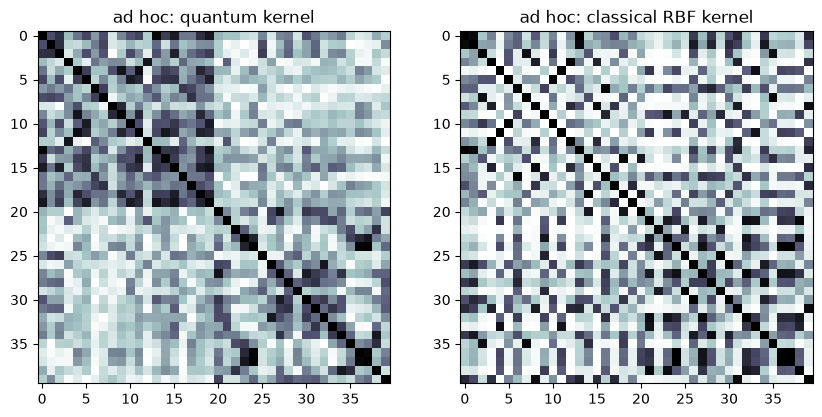

In [6]:
plot_kernels(qkernel.evaluate(x_vec=train_features),
             rbf_kernel(train_features, gamma=1 / (feature_dim * train_features.var())),
             'ad hoc')

## Part 2 – a real-world dataset: breast cancer

The Wisconsin breast-cancer dataset has 30 features.  As in `402`, we standardise them, reduce
them with PCA to the first **2 principal components** (one qubit each) and scale to $[-1, 1]$.

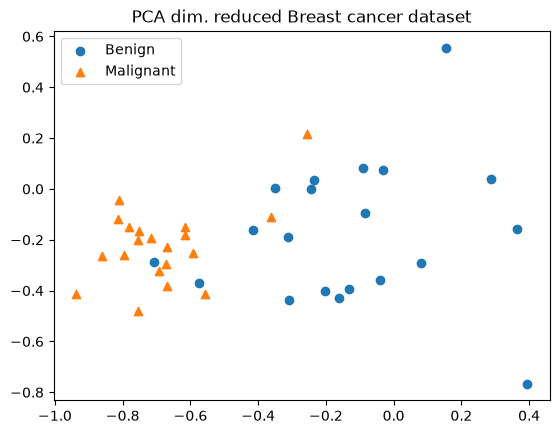

In [7]:
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

def prepare_dataset(loader, training_size, test_size, n, split, random_state):
    """Aqua's dataset recipe: standardise, PCA to n features, scale to [-1, 1], then take
    training_size / test_size samples per class. Returns feature/label arrays."""
    data, target = loader(return_X_y=True)
    x_train, x_test, y_train, y_test = train_test_split(data, target, test_size=split, random_state=random_state)
    std = StandardScaler().fit(x_train)
    x_train, x_test = std.transform(x_train), std.transform(x_test)
    pca = PCA(n_components=n).fit(x_train)
    x_train, x_test = pca.transform(x_train), pca.transform(x_test)
    minmax = MinMaxScaler((-1, 1)).fit(np.append(x_train, x_test, axis=0))
    x_train, x_test = minmax.transform(x_train), minmax.transform(x_test)
    def take(x, y, size):
        idx = np.concatenate([np.flatnonzero(y == c)[:size] for c in np.unique(target)])
        return x[idx], y[idx]
    return take(x_train, y_train, training_size) + take(x_test, y_test, test_size)

feature_dim = 2
train_features, train_labels, test_features, test_labels = prepare_dataset(
    datasets.load_breast_cancer, training_size=20, test_size=10, n=feature_dim, split=0.3, random_state=109)
class_labels = ['Benign', 'Malignant']
for c, marker in zip((0, 1), ('o', '^')):
    plt.scatter(*train_features[train_labels == c].T, marker=marker, label=class_labels[c])
plt.legend()
plt.title('PCA dim. reduced Breast cancer dataset')
plt.show()

In [8]:
feature_map = zz_feature_map(feature_dimension=feature_dim, reps=2, entanglement='linear')
qkernel = FidelityQuantumKernel(feature_map=feature_map)
qsvm = QSVC(quantum_kernel=qkernel)
qsvm.fit(train_features, train_labels)
print(f'QSVC testing accuracy:          {qsvm.score(test_features, test_labels):.2f}')

svm = SVC(kernel='rbf', gamma='scale').fit(train_features, train_labels)
print(f'Classical SVM testing accuracy: {svm.score(test_features, test_labels):.2f}')

QSVC testing accuracy:          0.75
Classical SVM testing accuracy: 0.95


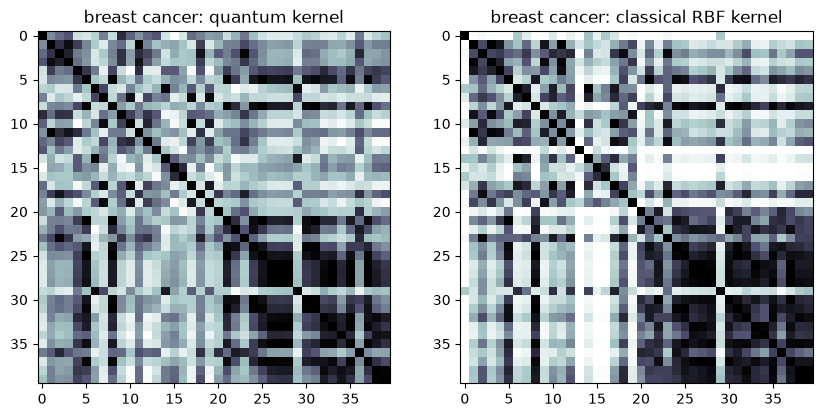

In [9]:
plot_kernels(qkernel.evaluate(x_vec=train_features),
             rbf_kernel(train_features, gamma=1 / (feature_dim * train_features.var())),
             'breast cancer')

On this real dataset the classical kernel is at least as good as the quantum one.  That is
the honest, typical picture today: a quantum kernel helps only when its feature space matches
the structure of the data – as with the ad hoc dataset, which was built for it.

### QSVC predictions on the test data
Blue = training data, green = correctly classified test point, red = wrong.

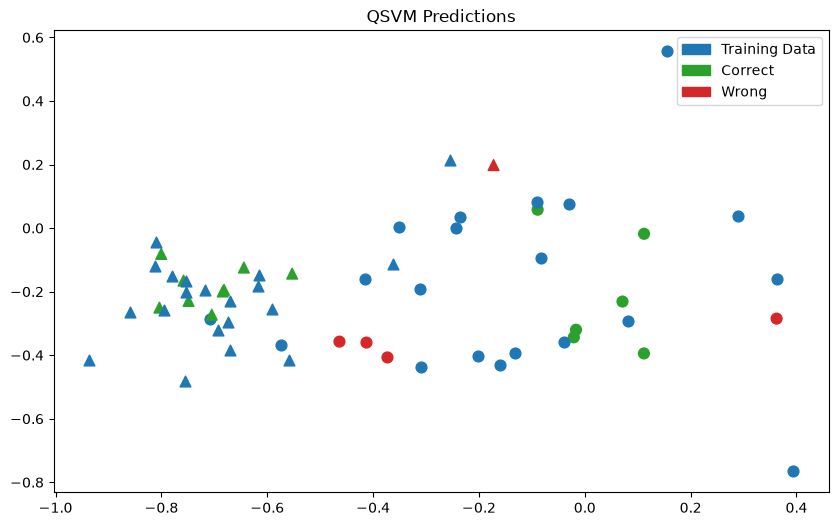

In [10]:
predicted = qsvm.predict(test_features)
markers = ['o', '^']
plt.figure(figsize=(10, 6))
plt.title('QSVM Predictions')
for c, marker in enumerate(markers):
    sel = test_labels == c
    plt.scatter(test_features[sel, 0], test_features[sel, 1], s=60, marker=marker,
                color=['tab:green' if p == c else 'tab:red' for p in predicted[sel]])
    plt.scatter(*train_features[train_labels == c].T, color='tab:blue', s=60, marker=marker)
train = mpatches.Patch(color='tab:blue', label='Training Data')
correct = mpatches.Patch(color='tab:green', label='Correct')
error = mpatches.Patch(color='tab:red', label='Wrong')
plt.legend(handles=[train, correct, error])
plt.show()

## Key takeaways
* A **quantum kernel** is the state overlap $|\langle\phi(x)|\phi(x')\rangle|^2$; only the
  feature map is quantum, the SVM is classical.
* No variational training ⇒ no optimiser, no barren plateaus – but the kernel costs one
  circuit per *pair* of points, i.e. it grows quadratically with the dataset.
* Quantum ≠ automatically better: compare against a classical baseline every time.

## Try it yourself
1. Use `reps=1` or `entanglement='full'` in the feature map.  How do accuracy and the kernel picture change?
2. Use 3 PCA components (`feature_dim = 3`) for the breast-cancer data.
3. Try `gamma` values 0.1, 1, 10 for the classical SVM.  Can it beat the QSVC on the ad hoc data?

**Next:** `416-QSVM-Multiclass` – more than two classes.